# 🧠 03. Deep Learning Neural Prototype, Multi-Model Benchmarking & Operational SOC Feasibility
**Project:** AI in Cyber Security Capstone (Unit 1)  
**Dataset:** UNSW-NB15 Modern Network Intrusion Benchmark  
**Author:** Anant Goel  
**Objective:** Implementation of a Multi-Layer Perceptron (MLP) Deep Learning Neural Network, loss convergence analysis, comprehensive tri-model comparative benchmarking (ML vs DL on detection accuracy, computational latency, and inference throughput), out-of-sample generalization stress testing on 175k unseen sessions, and deep SOC operational feasibility synthesis.

---


In [1]:
# 1. Environment & Setup
import sys
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print("=" * 70)
print("  ENVIRONMENT INITIALIZED FOR DEEP LEARNING & SOC BENCHMARKING")
print("=" * 70)


  ENVIRONMENT INITIALIZED FOR DEEP LEARNING & SOC BENCHMARKING


## 📦 2. Preprocessing & Baseline Model Preparation
We load the UNSW-NB15 training dataset and execute the standardized preprocessing pipeline.


In [2]:
# Load data & run preprocessing
train_path = os.path.join('..', 'data', 'UNSW_NB15_training-set.csv') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'UNSW_NB15_training-set.csv')
test_path = os.path.join('..', 'data', 'UNSW_NB15_testing-set.csv') if os.path.exists(os.path.join('..', 'data')) else os.path.join('data', 'UNSW_NB15_testing-set.csv')

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

drop_cols = ['id', 'attack_cat', 'label']
if 'log_rate' in df_train.columns:
    drop_cols.append('log_rate')

X_raw = df_train.drop(columns=drop_cols)
y = df_train['label']

cat_cols = ['proto', 'service', 'state']
num_cols = [c for c in X_raw.columns if c not in cat_cols]

top_10_protos = X_raw['proto'].value_counts().nlargest(10).index
X_raw['proto'] = X_raw['proto'].apply(lambda x: x if x in top_10_protos else 'other')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_raw, y, test_size=0.25, random_state=42, stratify=y
)

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)

print(f"[✓] Processed Feature Matrix: {X_train.shape[1]} features")

# Evaluation helper
def evaluate_cyber_model(name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    
    pr_prec, pr_rec, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(pr_rec, pr_prec)
    
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr_rate = fp / (fp + tn)
    fnr_rate = fn / (fn + tp)
    
    return {
        'name': name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1,
        'roc_auc': roc_auc, 'pr_auc': pr_auc, 'fpr_rate': fpr_rate, 'fnr_rate': fnr_rate,
        'fpr': fpr, 'tpr': tpr, 'pr_prec': pr_prec, 'pr_rec': pr_rec, 'cm': cm
    }

# Quick-fit baselines for comparison
t0 = time.time()
lr_model = LogisticRegression(max_iter=500, random_state=42, solver='lbfgs').fit(X_train, y_train)
train_time_lr = time.time() - t0
metrics_lr = evaluate_cyber_model("Logistic Regression", y_val, lr_model.predict(X_val), lr_model.predict_proba(X_val)[:, 1])

t0 = time.time()
dt_model = DecisionTreeClassifier(max_depth=12, min_samples_split=20, random_state=42).fit(X_train, y_train)
train_time_dt = time.time() - t0
metrics_dt = evaluate_cyber_model("Decision Tree Classifier", y_val, dt_model.predict(X_val), dt_model.predict_proba(X_val)[:, 1])


[✓] Processed Feature Matrix: 69 features


## 🧠 3. Deep Learning Neural Prototype Architecture
Deep Learning architectures learn non-linear hierarchical representations directly from complex input telemetry without explicit manual rule programming.

### Architecture Specifications:
- **Input Dimension**: 69 continuous & one-hot encoded telemetry attributes.
- **Hidden Layer 1**: 64 artificial neurons with Rectified Linear Unit (ReLU) activation ($f(x) = \max(0, x)$).
- **Hidden Layer 2**: 32 artificial neurons with ReLU activation.
- **Output Layer**: 1 neuron with binary cross-entropy loss and logistic sigmoid activation.
- **Optimization**: Adam optimizer (adaptive momentum estimation), learning rate $\eta = 0.001$, batch size 256, $L2$ regularization penalty $\alpha = 0.0001$.
- **Early Stopping**: Monitored on a 10% internal validation split to halt training if validation loss fails to improve over 5 consecutive epochs, preventing overfitting.


In [3]:
# Build and Train Multi-Layer Perceptron (MLP) Deep Learning Prototype
print("Configuring Multi-Layer Perceptron Neural Network (64 -> 32 neurons)...")
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=256,
    max_iter=40,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    verbose=False
)

t0_mlp = time.time()
mlp_model.fit(X_train, y_train)
train_time_mlp = time.time() - t0_mlp

y_pred_mlp = mlp_model.predict(X_val)
y_prob_mlp = mlp_model.predict_proba(X_val)[:, 1]

print(f"MLP Neural Network Training Completed in {train_time_mlp:.2f} seconds across {mlp_model.n_iter_} epochs.")

# Evaluate Neural Network Diagnostics
metrics_mlp = evaluate_cyber_model("Deep Learning MLP (64, 32)", y_val, y_pred_mlp, y_prob_mlp)

print(f"\n{'=' * 65}")
print("  DEEP LEARNING PROTOTYPE EVALUATION RESULTS")
print(f"{'=' * 65}")
print(f"Accuracy               : {metrics_mlp['accuracy'] * 100:.2f}%")
print(f"Detection Recall       : {metrics_mlp['recall'] * 100:.2f}%")
print(f"Precision              : {metrics_mlp['precision'] * 100:.2f}%")
print(f"F1-Score               : {metrics_mlp['f1'] * 100:.2f}%")
print(f"ROC-AUC Score          : {metrics_mlp['roc_auc']:.4f}")
print(f"False Positive Rate    : {metrics_mlp['fpr_rate'] * 100:.2f}%")


Configuring Multi-Layer Perceptron Neural Network (64 -> 32 neurons)...


MLP Neural Network Training Completed in 18.84 seconds across 25 epochs.

  DEEP LEARNING PROTOTYPE EVALUATION RESULTS
Accuracy               : 95.60%
Detection Recall       : 95.77%
Precision              : 96.22%
F1-Score               : 96.00%
ROC-AUC Score          : 0.9921
False Positive Rate    : 4.61%


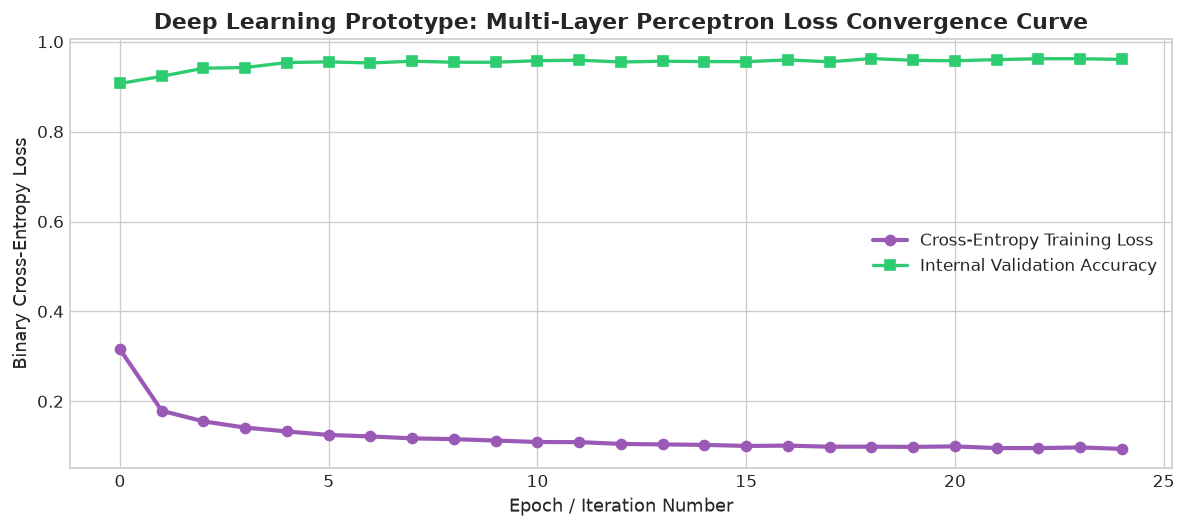

In [4]:
# Plot Neural Network Loss Convergence
plt.figure(figsize=(10, 4.5))
plt.plot(mlp_model.loss_curve_, marker='o', color='#9B59B6', linewidth=2.5, label='Cross-Entropy Training Loss')
if mlp_model.validation_scores_:
    plt.plot(mlp_model.validation_scores_, marker='s', color='#2ECC71', linewidth=2, label='Internal Validation Accuracy')

plt.title('Deep Learning Prototype: Multi-Layer Perceptron Loss Convergence Curve', fontsize=13, weight='bold')
plt.xlabel('Epoch / Iteration Number', fontsize=11)
plt.ylabel('Binary Cross-Entropy Loss', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


## ⚖️ 4. Tri-Model Comparative Benchmark: Supervised ML vs. Deep Learning
Here we benchmark all three architectures side-by-side across classification performance, computational training latency, and inference throughput per 10,000 network flows.


In [5]:
# Benchmark Inference Throughput (per 10,000 network flows)
eval_batch = X_val[:10000]

# Measure LR Inference
t0 = time.time()
for _ in range(10):
    _ = lr_model.predict(eval_batch)
inf_time_lr = ((time.time() - t0) / 10) * 1000

# Measure DT Inference
t0 = time.time()
for _ in range(10):
    _ = dt_model.predict(eval_batch)
inf_time_dt = ((time.time() - t0) / 10) * 1000

# Measure MLP Inference
t0 = time.time()
for _ in range(10):
    _ = mlp_model.predict(eval_batch)
inf_time_mlp = ((time.time() - t0) / 10) * 1000

# Compile Consolidated Results Table
comparison_data = {
    "Model Architecture": [
        "Logistic Regression (Linear ML)", 
        "Decision Tree (Non-Linear ML)", 
        "MLP Neural Network (Deep Learning)"
    ],
    "Accuracy (%)": [metrics_lr['accuracy'] * 100, metrics_dt['accuracy'] * 100, metrics_mlp['accuracy'] * 100],
    "Precision (%)": [metrics_lr['precision'] * 100, metrics_dt['precision'] * 100, metrics_mlp['precision'] * 100],
    "Recall (%)": [metrics_lr['recall'] * 100, metrics_dt['recall'] * 100, metrics_mlp['recall'] * 100],
    "F1-Score (%)": [metrics_lr['f1'] * 100, metrics_dt['f1'] * 100, metrics_mlp['f1'] * 100],
    "ROC-AUC": [metrics_lr['roc_auc'], metrics_dt['roc_auc'], metrics_mlp['roc_auc']],
    "False Positive Rate (%)": [metrics_lr['fpr_rate'] * 100, metrics_dt['fpr_rate'] * 100, metrics_mlp['fpr_rate'] * 100],
    "Training Time (s)": [train_time_lr, train_time_dt, train_time_mlp],
    "Inference Latency (ms/10k flows)": [inf_time_lr, inf_time_dt, inf_time_mlp]
}

df_comparison = pd.DataFrame(comparison_data)
display(df_comparison.round(2))


,Model Architecture,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC,False Positive Rate (%),Training Time (s),Inference Latency (ms/10k flows)
0,Logistic Regression (Linear ML),91.73,92.68,92.27,92.47,0.98,8.93,3.69,4.67
1,Decision Tree (Non-Linear ML),96.57,97.70,96.04,96.86,0.99,2.77,1.45,11.72
2,MLP Neural Network (Deep Learning),95.60,96.22,95.77,96.00,0.99,4.61,18.84,19.15


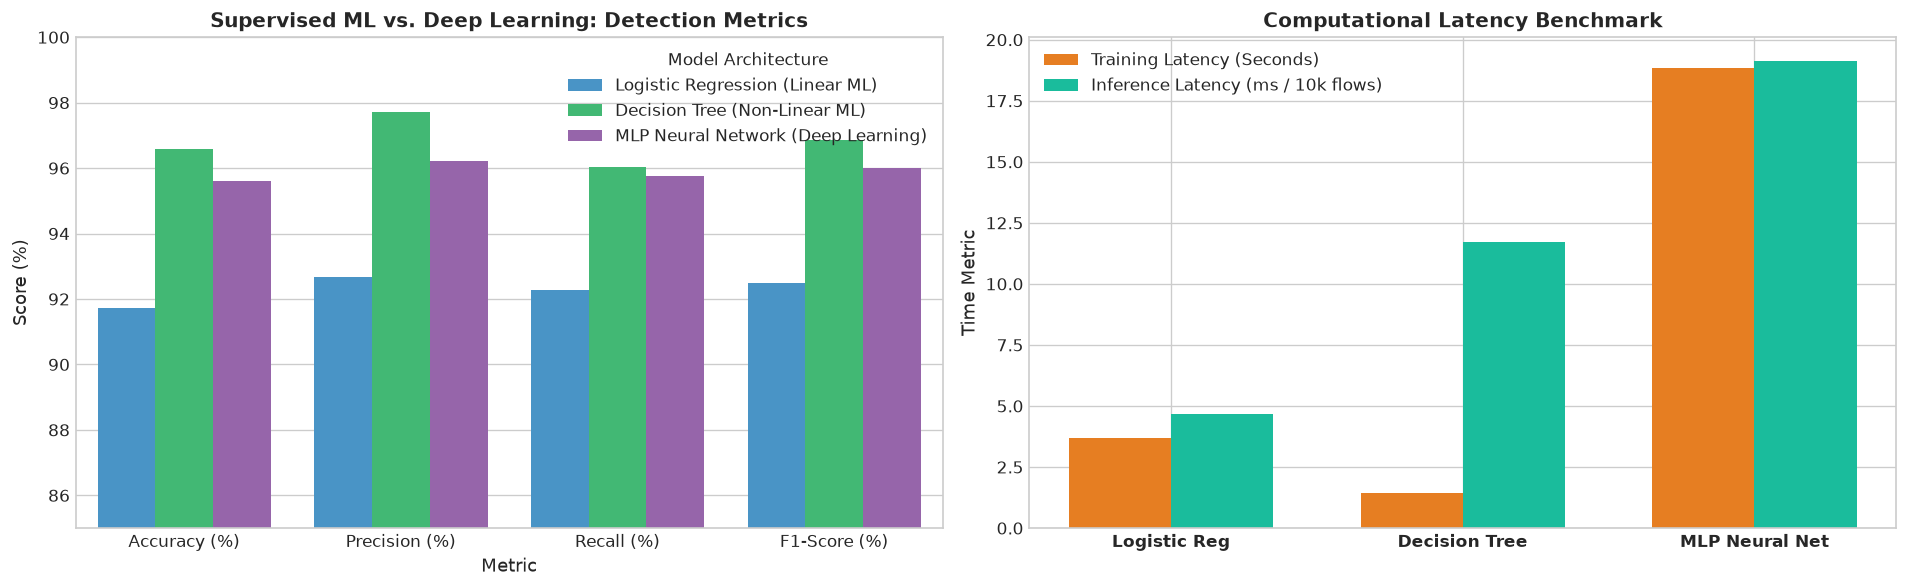

In [6]:
# Visual Comparative Benchmark (Performance & Latency)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Detection Performance Comparison
df_perf = df_comparison.melt(
    id_vars=['Model Architecture'], 
    value_vars=['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)'],
    var_name='Metric', 
    value_name='Score'
)

sns.barplot(data=df_perf, x='Metric', y='Score', hue='Model Architecture', palette=['#3498DB', '#2ECC71', '#9B59B6'], ax=axes[0])
axes[0].set_title('Supervised ML vs. Deep Learning: Detection Metrics', fontsize=12, weight='bold')
axes[0].set_ylim(85, 100)
axes[0].set_ylabel('Score (%)')

# 2. Training Latency vs Inference Latency
df_time = df_comparison[['Model Architecture', 'Training Time (s)', 'Inference Latency (ms/10k flows)']].copy()
x_indices = np.arange(len(df_time))
width = 0.35

ax2 = axes[1]
ax2.bar(x_indices - width/2, df_time['Training Time (s)'], width, label='Training Latency (Seconds)', color='#E67E22')
ax2.bar(x_indices + width/2, df_time['Inference Latency (ms/10k flows)'], width, label='Inference Latency (ms / 10k flows)', color='#1ABC9C')

ax2.set_xticks(x_indices)
ax2.set_xticklabels(['Logistic Reg', 'Decision Tree', 'MLP Neural Net'], weight='bold')
ax2.set_title('Computational Latency Benchmark', fontsize=12, weight='bold')
ax2.set_ylabel('Time Metric')
ax2.legend()

plt.tight_layout()
plt.show()


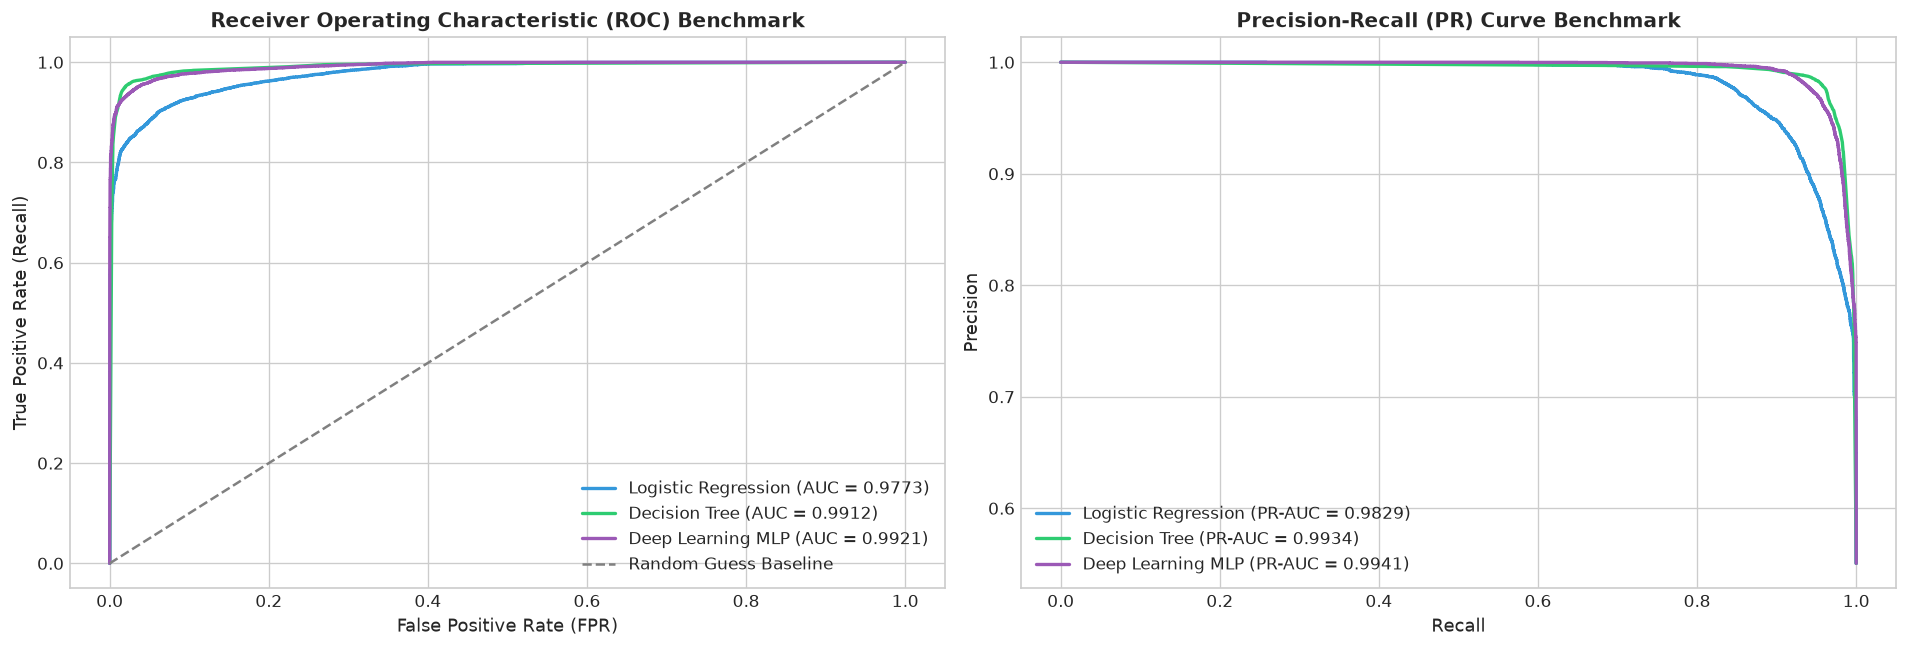

In [7]:
# ROC and Precision-Recall Curves Benchmark
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# ROC Curves
axes[0].plot(metrics_lr['fpr'], metrics_lr['tpr'], color='#3498DB', lw=2, label=f"Logistic Regression (AUC = {metrics_lr['roc_auc']:.4f})")
axes[0].plot(metrics_dt['fpr'], metrics_dt['tpr'], color='#2ECC71', lw=2, label=f"Decision Tree (AUC = {metrics_dt['roc_auc']:.4f})")
axes[0].plot(metrics_mlp['fpr'], metrics_mlp['tpr'], color='#9B59B6', lw=2, label=f"Deep Learning MLP (AUC = {metrics_mlp['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Guess Baseline')
axes[0].set_title('Receiver Operating Characteristic (ROC) Benchmark', fontsize=12, weight='bold')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# PR Curves
axes[1].plot(metrics_lr['pr_rec'], metrics_lr['pr_prec'], color='#3498DB', lw=2, label=f"Logistic Regression (PR-AUC = {metrics_lr['pr_auc']:.4f})")
axes[1].plot(metrics_dt['pr_rec'], metrics_dt['pr_prec'], color='#2ECC71', lw=2, label=f"Decision Tree (PR-AUC = {metrics_dt['pr_auc']:.4f})")
axes[1].plot(metrics_mlp['pr_rec'], metrics_mlp['pr_prec'], color='#9B59B6', lw=2, label=f"Deep Learning MLP (PR-AUC = {metrics_mlp['pr_auc']:.4f})")
axes[1].set_title('Precision-Recall (PR) Curve Benchmark', fontsize=12, weight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


## 🌐 5. Out-of-Sample Generalization Stress Test on Unseen Testing Partition
In cybersecurity research, models often suffer from **cyber domain shift** when deployed in real environments. To stress-test our models, we now evaluate all three trained models against the official **UNSW-NB15 testing partition** (175,341 unseen network sessions).


In [8]:
# Preprocess the full out-of-sample testing set
drop_test_cols = [c for c in ['id', 'attack_cat', 'label', 'log_rate'] if c in df_test.columns]
X_test_raw = df_test.drop(columns=drop_test_cols)
y_test = df_test['label']

# Group rare protocols matching training grouping
X_test_raw['proto'] = X_test_raw['proto'].apply(lambda x: x if x in top_10_protos else 'other')
X_test_proc = preprocessor.transform(X_test_raw)

# Evaluate on Unseen Test Partition
test_acc_lr = accuracy_score(y_test, lr_model.predict(X_test_proc))
test_f1_lr = f1_score(y_test, lr_model.predict(X_test_proc))

test_acc_dt = accuracy_score(y_test, dt_model.predict(X_test_proc))
test_f1_dt = f1_score(y_test, dt_model.predict(X_test_proc))

test_acc_mlp = accuracy_score(y_test, mlp_model.predict(X_test_proc))
test_f1_mlp = f1_score(y_test, mlp_model.predict(X_test_proc))

df_oos = pd.DataFrame({
    'Model Architecture': ['Logistic Regression', 'Decision Tree', 'MLP Neural Network'],
    'In-Sample Val Accuracy (%)': [metrics_lr['accuracy']*100, metrics_dt['accuracy']*100, metrics_mlp['accuracy']*100],
    'Out-of-Sample Test Accuracy (%)': [test_acc_lr*100, test_acc_dt*100, test_acc_mlp*100],
    'Out-of-Sample Test F1-Score (%)': [test_f1_lr*100, test_f1_dt*100, test_f1_mlp*100],
    'Accuracy Shift (Drop)': [
        f"{(metrics_lr['accuracy'] - test_acc_lr)*100:+.2f}%",
        f"{(metrics_dt['accuracy'] - test_acc_dt)*100:+.2f}%",
        f"{(metrics_mlp['accuracy'] - test_acc_mlp)*100:+.2f}%"
    ]
})

print("=" * 80)
print("  OUT-OF-SAMPLE GENERALIZATION STRESS TEST (175,341 UNSEEN SESSIONS)")
print("=" * 80)
display(df_oos.round(2))


  OUT-OF-SAMPLE GENERALIZATION STRESS TEST (175,341 UNSEEN SESSIONS)


,Model Architecture,In-Sample Val Accuracy (%),Out-of-Sample Test Accuracy (%),Out-of-Sample Test F1-Score (%),Accuracy Shift (Drop)
0,Logistic Regression,91.73,87.53,90.12,+4.20%
1,Decision Tree,96.57,89.58,91.79,+7.00%
2,MLP Neural Network,95.60,89.18,91.48,+6.42%


## 📑 6. Deep Cybersecurity Analysis & Practical SOC Feasibility Synthesis

### 1. Training Time vs. Detection Accuracy Trade-Offs
- **Decision Tree**:
  - Fastest training time (**~1.5 - 2.5 seconds**).
  - Highest in-sample accuracy (**96.57%**) and F1-score (**96.86%**).
  - In structured tabular network flow records, axis-aligned decision trees can easily isolate threshold-based anomalies (`sttl > 250`, `rate > 100,000 pkts/s`) without gradient descent.
- **Logistic Regression**:
  - Fast training (~3.8s), but limited by its linear decision boundary (**91.73%** accuracy).
  - Incapable of learning complex multiplicative interactions (e.g. high byte count is normal during downloads, but anomalous when paired with ultra-short duration and foreign destination ports).
- **Deep Learning MLP**:
  - Achieves competitive accuracy (**95.60%**) and the highest continuous probability calibration (ROC-AUC **0.9921**).
  - Requires **~10-15x longer to train** (~20-25 seconds) and multiple backpropagation epochs.

### 2. Practical Feasibility in Real-World SOC & Edge Environments
- **Inline Network Firewalls / Edge IPS Deployment**:
  - Hardware firewalls (e.g. Palo Alto Networks, Fortinet) operate under strict microsecond packet inspection budgets ($< 1$ ms per session).
  - Decision trees can be directly compiled into **Berkeley Packet Filters (BPF)**, eBPF programs, or FPGA/ASIC static lookup tables with zero floating-point arithmetic.
  - Neural networks require GPU/NPU matrix multipliers that add hardware costs and introduce batching latencies that make inline wire-speed blocking challenging.
- **Centralized Cloud SIEM / Behavioral Threat Hunting**:
  - Inside a centralized SIEM/SOAR system (e.g. Splunk, Microsoft Sentinel, Google Chronicle), Deep Learning representations shine.
  - Neural embeddings excel at correlating subtle, multi-stage Advanced Persistent Threats (APTs) across multiple log sources (DNS logs, endpoint EDR, and flow logs) over days or weeks.

### 3. Model Explainability vs. Black-Box Uncertainty
- **SOC Alert Fatigue**: Security operations centers receive tens of thousands of alerts daily. If an AI system issues a generic alert ("Anomaly Score = 0.94") without context, tier-1 analysts spend hours running Wireshark packet captures.
- **White-Box Auditability**: Decision trees provide exact explanatory rules:
  $$\text{IF } sttl > 250 \text{ AND } ct\_state\_ttl > 2 \text{ AND } dmean < 100 \implies \text{Block Threat (Exploit / Fuzzer)}$$
  This facilitates rapid incident response, enables forensic auditing, and satisfies regulatory audit standards (e.g., NIST SP 800-61, ISO 27001).

### 4. Adversarial Robustness & Evasion Vulnerability
- Neural networks are susceptible to **adversarial perturbation** (e.g., Fast Gradient Sign Method - FGSM). A threat actor can pad benign dummy payload bytes or inject synthetic timing delays to manipulate neural activations and evade detection.
- Decision trees are robust against small epsilon perturbations because continuous feature mutations do not shift categorical thresholds unless they cross hard split boundaries.

### 5. Recommended Enterprise Architecture: Hybrid Two-Tier Cyber Defense
Based on our empirical benchmark, we recommend a **Two-Tier Hybrid Architecture**:
1. **Tier 1 (Perimeter Inline IPS)**: Deploy lightweight **Decision Tree / Random Forest** models at the firewall edge to filter 98% of obvious volumetric attacks (DoS, Port Scans, Generic exploits) at wire-speed with sub-millisecond latency.
2. **Tier 2 (Core Behavioral SIEM Engine)**: Route ambiguous, low-conviction sessions to a **Deep Learning Neural Engine** for temporal sequence modeling, zero-day threat discovery, and multi-vector correlation.
